# Pruebas de modelos: primer baseline

El objetivo es predecir la **facturación diaria suponiendo que la tienda abre**. Trabajaremos únicamente con los días abiertos: según la operativa documentada en el EDA, un total positivo corresponde a un día abierto y un total igual a cero, a un cierre.

En este primer paso probamos un baseline sencillo. Después podremos comparar otros modelos bajo el mismo protocolo. El archivo utilizado es exclusivamente el Gold real de `data/processed/ventas_gold.csv`.

**Confidencialidad:** las salidas se expresan en índices, porcentajes y recuentos, no en euros. Aun así, pueden contener información comercial sensible: revisa y borra las salidas antes de compartir el notebook.

## 1. Carga y controles básicos

Comprobamos que hay una fecha por cada día de 2022 a 2025, sin duplicados, y que los totales son numéricos y no negativos. No rellenamos fechas ausentes: una fecha ausente no demuestra que la tienda cerrara. Los importes se necesitan internamente para construir el índice, pero no se muestran.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = PROJECT_ROOT / "data" / "processed" / "ventas_gold.csv"

ventas = pd.read_csv(DATASET, encoding="utf-8-sig", dtype=str)
columnas_necesarias = {"fecha", "total"}
faltantes = columnas_necesarias - set(ventas.columns)
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")

ventas = ventas[["fecha", "total"]].copy()
ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="mixed", errors="coerce")
texto_total = ventas["total"].str.replace("€", "", regex=False).str.replace(" ", "", regex=False)
formato_espanol = texto_total.str.contains(",", na=False)
texto_total.loc[formato_espanol] = (
    texto_total.loc[formato_espanol].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
)
ventas["total"] = pd.to_numeric(texto_total, errors="coerce")

fechas_esperadas = pd.date_range("2022-01-01", "2025-12-31", freq="D")
fechas_validas = ventas["fecha"].dropna()
controles = pd.Series({
    "Fechas inválidas": int(ventas["fecha"].isna().sum()),
    "Fechas duplicadas": int(fechas_validas.duplicated().sum()),
    "Fechas fuera del periodo": int((~fechas_validas.isin(fechas_esperadas)).sum()),
    "Fechas ausentes": len(fechas_esperadas.difference(fechas_validas)),
    "Totales no numéricos o infinitos": int((~np.isfinite(ventas["total"])).sum()),
    "Totales negativos": int(ventas["total"].lt(0).sum()),
}, name="Incidencias")
display(controles.to_frame())
if controles.gt(0).any():
    raise ValueError("Revisa las incidencias antes de continuar.")
print("Controles superados.")

,Incidencias
Fechas inválidas,0
Fechas duplicadas,0
Fechas fuera del periodo,0
Fechas ausentes,0
Totales no numéricos o infinitos,0
Totales negativos,0


Controles superados.


## 2. Días abiertos e índice base 100

Filtramos los días abiertos y definimos **100 como la media diaria de los días abiertos de 2022**. Por ejemplo, un índice de 120 significa una venta un 20 % superior a esa media; 80 significa un 20 % inferior.

La misma referencia se usa en todas las evaluaciones. Como 2022 precede a todas ellas, el cálculo no utiliza información del periodo que se está prediciendo. A partir de aquí trabajamos con el índice, no con importes en euros.

In [2]:
ventas = ventas.loc[ventas["total"].gt(0)].sort_values("fecha").copy()
base_2022 = ventas.loc[ventas["fecha"].dt.year.eq(2022), "total"].mean()
if not np.isfinite(base_2022) or base_2022 <= 0:
    raise ValueError("No se puede calcular la referencia: revisa las ventas de los días abiertos de 2022.")
ventas["indice"] = 100 * ventas["total"] / base_2022
abiertos = ventas[["fecha", "indice"]].reset_index(drop=True)
del ventas, texto_total, base_2022

aperturas = abiertos.groupby(abiertos["fecha"].dt.year).size().rename("Días abiertos")
aperturas.index.name = "Año"
display(aperturas.to_frame())
print("Índice calculado con base en los días abiertos de 2022.")

,Días abiertos
Año,
2022,355
2023,311
2024,307
2025,308


Índice calculado con base en los días abiertos de 2022.


## 3. Baseline: mediana histórica por día de la semana

Para cada fecha, predecimos la **mediana de los índices observados en días abiertos del mismo día de la semana**, usando únicamente datos anteriores al inicio del periodo predicho. Así, todos los sábados de un mismo periodo reciben la misma predicción, todos los domingos otra, etc. La mediana es menos sensible a ventas excepcionalmente altas o bajas que la media.

Este baseline recoge la estacionalidad semanal, pero **no distingue meses ni festivos**. No utiliza un lag de siete días, ya que el día correspondiente podría estar cerrado y, al predecir un periodo completo, no conocemos las ventas de sus semanas anteriores.

Generamos una predicción para cada fecha natural, como si fuera a abrir, sin consultar si abrió. Solo después, para medir el error, conservamos las fechas realmente abiertas. Si no existen días abiertos de alguna categoría semanal en entrenamiento, el proceso se detiene: no inventamos una predicción.

In [3]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

def predecir_baseline(datos, inicio, fin):
    inicio = pd.Timestamp(inicio)
    fin = pd.Timestamp(fin)
    entrenamiento = datos.loc[datos["fecha"] < inicio].copy()
    medianas = entrenamiento.groupby(entrenamiento["fecha"].dt.day_of_week)["indice"].median()
    dias_sin_historial = sorted(set(range(7)) - set(medianas.index))
    if dias_sin_historial:
        nombres = [DIAS[dia] for dia in dias_sin_historial]
        raise ValueError(f"No hay días abiertos de entrenamiento para: {', '.join(nombres)}")
    predicciones = pd.DataFrame({"fecha": pd.date_range(inicio, fin, freq="D")})
    predicciones["prediccion"] = predicciones["fecha"].dt.day_of_week.map(medianas)
    return predicciones

def evaluar_periodo(datos, inicio, fin):
    predicciones = predecir_baseline(datos, inicio, fin)
    reales = datos.loc[datos["fecha"].between(pd.Timestamp(inicio), pd.Timestamp(fin))]
    comparacion = reales.merge(predicciones, on="fecha", how="left", validate="one_to_one")
    if comparacion.empty or comparacion["prediccion"].isna().any():
        raise ValueError("El periodo no tiene días abiertos o faltan predicciones para evaluarlos.")
    return comparacion

def metricas(comparacion):
    if comparacion.empty or not np.isfinite(comparacion["indice"]).all() or comparacion["indice"].le(0).any():
        raise ValueError("El MAPE requiere índices reales finitos y positivos en todos los días evaluados.")
    error = comparacion["prediccion"] - comparacion["indice"]
    return pd.Series({
        "Días abiertos": len(comparacion),
        "MAE (puntos de índice)": error.abs().mean(),
        "MAPE (%)": 100 * error.abs().div(comparacion["indice"]).mean(),
        "WAPE (%)": 100 * error.abs().sum() / comparacion["indice"].sum(),
        "Sesgo (puntos de índice)": error.mean(),
    })

## 4. Validación temporal trimestral: 2023 y 2024

En cada corte usamos todos los días abiertos anteriores al trimestre y predecimos el trimestre completo de una vez. Por ejemplo, para abril–junio de 2023 se puede entrenar con enero–marzo de 2023, pero no con las ventas de abril–junio. Esto se repite hasta el último trimestre de 2024.

**MAE** es el error absoluto medio en puntos de índice: cuanto menor, mejor. **MAPE** es la media de los errores porcentuales diarios; da el mismo peso a cada día, pero puede ser muy alto cuando el índice real es pequeño. **WAPE** divide la suma de errores absolutos entre la suma de los índices reales, dando más peso a los días con mayor venta. El **sesgo** es la media de predicción menos realidad: positivo indica sobrepredicción y negativo, infrapredicción. Se calculan solo sobre días abiertos, cuyos índices reales son positivos.

Estas pruebas son previsiones a tres meses; no demuestran por sí solas el rendimiento de una previsión anual. Los resultados trimestrales sirven para explorar el baseline sin usar 2025 para ajustar su diseño.

In [4]:
resultados_validacion = []
resumen_validacion = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    inicio = trimestre.start_time
    fin = trimestre.end_time.normalize()
    resultado = evaluar_periodo(abiertos, inicio, fin)
    resultado["trimestre"] = str(trimestre)
    resultados_validacion.append(resultado)
    resumen_validacion.append(metricas(resultado).rename(str(trimestre)))

validacion = pd.concat(resultados_validacion, ignore_index=True)
tabla_validacion = pd.DataFrame(resumen_validacion)
tabla_validacion.index.name = "Trimestre"
display(tabla_validacion.round(2))
print("Resumen conjunto de los días abiertos de validación:")
display(metricas(validacion).round(2).to_frame("Validación 2023–2024"))

,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Trimestre,,,,,
2023Q1,78.0,23.06,34.30,24.56,6.59
2023Q2,81.0,25.78,26.37,23.95,-8.95
2023Q3,77.0,33.70,25.61,27.35,-21.24
2023Q4,75.0,32.09,59.77,26.33,-18.44
2024Q1,77.0,28.70,28.72,26.72,-2.52
2024Q2,76.0,28.36,27.57,25.92,-5.96
2024Q3,78.0,30.57,28.51,27.40,-7.27
2024Q4,76.0,31.23,25.13,26.02,-16.10


Resumen conjunto de los días abiertos de validación:


,Validación 2023–2024
Días abiertos,618.00
MAE (puntos de índice),29.14
MAPE (%),31.89
WAPE (%),26.07
Sesgo (puntos de índice),-9.17


## 5. Test final: 2025 completo

Ahora calculamos las medianas usando **solo 2022–2024** y generamos todas las predicciones de 2025 de una vez. Ninguna venta real de 2025 interviene en las predicciones; después se comparan con los días que efectivamente abrieron.

Esta evaluación es retrospectiva y condicionada a los días que abrieron: no mide si se habría acertado el calendario de apertura. Los resultados de 2025 deben reservarse para la comparación final, no para ajustar el baseline u otros modelos.

In [5]:
test_2025 = evaluar_periodo(abiertos, "2025-01-01", "2025-12-31")
display(metricas(test_2025).round(2).to_frame("Test 2025"))

,Test 2025
Días abiertos,308.00
MAE (puntos de índice),27.32
MAPE (%),32.12
WAPE (%),26.70
Sesgo (puntos de índice),1.61


### ¿Dónde se equivoca?

Desglosamos el test por día de la semana y por mes. El número de días abiertos es importante para interpretar cada resultado, especialmente los domingos: un error calculado con pocas observaciones es menos estable.

El gráfico compara la media de índices reales y previstos de los días abiertos de cada mes. No representa ventas de días cerrados ni una previsión anual realizada con un calendario de apertura conocido.

Errores por día de la semana:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Día de la semana,,,,,
Lunes,50.0,24.97,36.41,29.32,-1.51
Martes,51.0,26.57,35.15,29.14,5.46
Miércoles,52.0,25.90,33.75,29.46,3.75
Jueves,49.0,24.91,30.41,27.82,-1.76
Viernes,50.0,28.23,33.11,28.46,9.30
Sábado,51.0,29.84,19.23,18.45,-2.14
Domingo,5.0,62.27,79.74,69.87,-34.61


Errores por mes:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Mes,,,,,
1,25.0,22.92,33.89,26.15,17.31
2,24.0,26.56,24.85,24.82,-2.40
3,27.0,28.15,37.46,27.75,2.60
4,28.0,32.79,45.05,31.52,-3.71
5,26.0,30.38,34.27,29.32,3.31
6,24.0,24.54,29.22,25.54,8.02
7,27.0,26.57,34.81,28.46,9.90
8,24.0,22.73,18.36,19.34,-9.72
9,26.0,30.40,26.43,26.05,-13.19


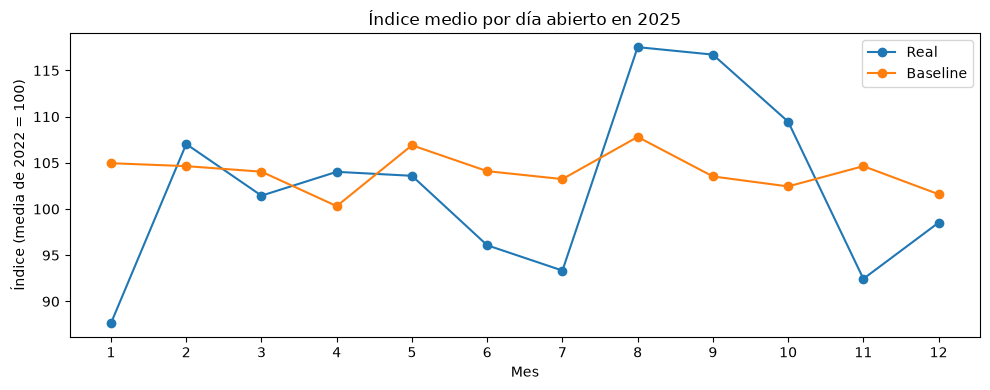

In [6]:
test_2025["dia_semana"] = test_2025["fecha"].dt.day_of_week
test_2025["mes"] = test_2025["fecha"].dt.month

por_dia = pd.DataFrame({DIAS[dia]: metricas(grupo) for dia, grupo in test_2025.groupby("dia_semana")}).T
por_dia.index.name = "Día de la semana"
print("Errores por día de la semana:")
display(por_dia.round(2))

por_mes = pd.DataFrame({mes: metricas(grupo) for mes, grupo in test_2025.groupby("mes")}).T
por_mes.index.name = "Mes"
print("Errores por mes:")
display(por_mes.round(2))

medias_mensuales = test_2025.groupby("mes")[["indice", "prediccion"]].mean()
ax = medias_mensuales.rename(columns={"indice": "Real", "prediccion": "Baseline"}).plot(
    marker="o", figsize=(10, 4), xticks=range(1, 13)
)
ax.set(title="Índice medio por día abierto en 2025", xlabel="Mes", ylabel="Índice (media de 2022 = 100)")
plt.tight_layout()
plt.show()

## 6. Comparación de baselines estacionales

Además de la mediana por día de la semana ya calculada, probamos cuatro referencias:

1. **Mediana mes y día:** por ejemplo, la mediana de todos los sábados abiertos de agosto disponibles antes del corte.
2. **Naïve anual:** el índice del mismo día de la semana y con el mismo orden dentro del año anterior. Por ejemplo, el primer lunes de 2025 se compara con el primer lunes de 2024.
3. **Media anual:** la media de los días equivalentes abiertos de los tres años anteriores disponibles. Para el primer lunes de 2025 se buscan los primeros lunes de 2022, 2023 y 2024.
4. **Mediana anual:** la mediana de esos mismos días equivalentes abiertos. Con dos valores coincide con la media y con uno toma ese único valor.

El orden se calcula sobre **fechas naturales**, no sobre filas de días abiertos. Si la fecha equivalente está cerrada o no existe (puede ocurrir con la 53.ª aparición de un día de la semana), la media y la mediana anuales utilizan los años equivalentes abiertos que haya; si no queda ninguno, utilizan la mediana histórica del mismo mes y día de la semana. El naïve anual utiliza esa misma mediana cuando falta su fecha equivalente. Si tampoco existe dicha combinación de mes y día, se utiliza la mediana histórica del día de la semana. Sin datos para ese día, la ejecución se detiene.

Estas reglas se aplican también a domingos y se fijan antes de evaluar. En la tabla de respaldos veremos cuántas predicciones recurrieron a ellas. Los pocos domingos abiertos pueden hacer menos estables sus estimaciones.

En cada corte solo se usan datos anteriores a su inicio. Las referencias anuales buscan años naturales anteriores al año predicho; por ello, en la primera validación solo hay un año disponible. Se generan predicciones para todas las fechas y se comparan después solo las que realmente abrieron.

In [7]:
def fecha_equivalente(fecha, anio):
    primero = pd.Timestamp(year=anio, month=1, day=1)
    ordinal = (fecha.day_of_year - 1) // 7
    desplazamiento = (fecha.day_of_week - primero.day_of_week) % 7 + 7 * ordinal
    equivalente = primero + pd.Timedelta(days=desplazamiento)
    return equivalente if equivalente.year == anio else None


def predecir_estacionales(datos, inicio, fin):
    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
    entrenamiento = datos.loc[datos["fecha"] < inicio].copy()
    historial = entrenamiento.set_index("fecha")["indice"].sort_index()
    mes_dia = entrenamiento.groupby(
        [entrenamiento["fecha"].dt.month, entrenamiento["fecha"].dt.day_of_week]
    )["indice"].median()
    dia = entrenamiento.groupby(entrenamiento["fecha"].dt.day_of_week)["indice"].median()
    semanal = predecir_baseline(datos, inicio, fin).set_index("fecha")["prediccion"]

    filas = []
    for fecha in pd.date_range(inicio, fin, freq="D"):
        mediana_mes = mes_dia.get((fecha.month, fecha.day_of_week), np.nan)
        if pd.notna(mediana_mes):
            respaldo, origen_respaldo = mediana_mes, "Mediana mes y día"
        elif fecha.day_of_week in dia.index:
            respaldo, origen_respaldo = dia.loc[fecha.day_of_week], "Mediana día semanal"
        else:
            raise ValueError(f"No hay días abiertos anteriores para {DIAS[fecha.day_of_week]}.")

        equivalentes = []
        for anio in range(fecha.year - 1, fecha.year - 4, -1):
            equivalente = fecha_equivalente(fecha, anio)
            if equivalente is not None and equivalente in historial.index:
                equivalentes.append((anio, historial.loc[equivalente]))

        anterior = next((valor for anio, valor in equivalentes if anio == fecha.year - 1), None)
        candidatos = [
            ("Mediana día semanal", semanal.loc[fecha], "Mediana día semanal", np.nan),
            ("Mediana mes y día", respaldo, origen_respaldo, np.nan),
            ("Naïve anual", anterior if anterior is not None else respaldo,
             "Año anterior" if anterior is not None else origen_respaldo, np.nan),
            ("Media anual", np.mean([valor for _, valor in equivalentes]) if equivalentes else respaldo,
             "Años equivalentes" if equivalentes else origen_respaldo, len(equivalentes)),
            ("Mediana anual", np.median([valor for _, valor in equivalentes]) if equivalentes else respaldo,
             "Años equivalentes" if equivalentes else origen_respaldo, len(equivalentes)),
        ]
        for modelo, prediccion, origen, n_anios in candidatos:
            filas.append({"fecha": fecha, "modelo": modelo, "prediccion": prediccion,
                          "origen": origen, "anios_equivalentes": n_anios})
    return pd.DataFrame(filas)


def evaluar_baselines(datos, inicio, fin):
    predicciones = predecir_estacionales(datos, inicio, fin)
    reales = datos.loc[datos["fecha"].between(pd.Timestamp(inicio), pd.Timestamp(fin))]
    resultado = predicciones.merge(reales, on="fecha", how="inner", validate="many_to_one")
    if resultado.empty or resultado["prediccion"].isna().any():
        raise ValueError("El periodo no tiene días abiertos o faltan predicciones para evaluarlos.")
    if len(resultado) != 5 * len(reales):
        raise ValueError("Los baselines no se evaluaron sobre los mismos días abiertos.")
    return resultado


def resumen_baselines(resultados):
    return pd.DataFrame({modelo: metricas(grupo) for modelo, grupo in resultados.groupby("modelo")}).T

### Validación trimestral

Repetimos los ocho cortes de 2023–2024 con los cinco baselines. En cada corte se predice el trimestre completo de una vez. El resumen conjunto calcula los errores sobre todos los días abiertos de validación, no es una media simple de los errores trimestrales. La segunda tabla permite comprobar si las diferencias se mantienen en distintas épocas del año.

In [8]:
cortes_baselines = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    resultado = evaluar_baselines(abiertos, trimestre.start_time, trimestre.end_time.normalize())
    resultado["trimestre"] = str(trimestre)
    cortes_baselines.append(resultado)

validacion_baselines = pd.concat(cortes_baselines, ignore_index=True)
print("Resumen conjunto de validación:")
display(resumen_baselines(validacion_baselines).round(2))

filas_trimestre = []
for (trimestre, modelo), grupo in validacion_baselines.groupby(["trimestre", "modelo"]):
    filas_trimestre.append({"Trimestre": trimestre, "Baseline": modelo, **metricas(grupo).to_dict()})
tabla_trimestres = pd.DataFrame(filas_trimestre).set_index(["Trimestre", "Baseline"])
print("Errores por trimestre:")
display(tabla_trimestres.round(2))

Resumen conjunto de validación:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Media anual,618.0,34.05,41.94,30.46,-4.52
Mediana anual,618.0,34.05,41.94,30.46,-4.52
Mediana día semanal,618.0,29.14,31.89,26.07,-9.17
Mediana mes y día,618.0,29.05,33.82,25.99,-6.92
Naïve anual,618.0,35.45,43.66,31.72,-2.87


Errores por trimestre:


Días abiertos  MAE (puntos de índice)  \
Trimestre Baseline                                                     
2023Q1    Media anual                   78.0                   27.80   
          Mediana anual                 78.0                   27.80   
          Mediana día semanal           78.0                   23.06   
          Mediana mes y día             78.0                   23.07   
          Naïve anual                   78.0                   27.80   
2023Q2    Media anual                   81.0                   35.80   
          Mediana anual                 81.0                   35.80   
          Mediana día semanal           81.0                   25.78   
          Mediana mes y día             81.0                   27.67   
          Naïve anual                   81.0                   35.80   
2023Q3    Media anual                   77.0                   36.74   
          Mediana anual                 77.0                   36.74   
          Mediana día semanal           77.0                   33.70   
          Mediana mes y día             77.0                   28.85   
          Naïve anual                   77.0                   36.74   
2023Q4    Media anual                   75.0                   36.35   
          Mediana anual                 75.0                   36.35   
          Mediana día semanal           75.0                   32.09   
          Mediana mes y día             75.0                   31.88   
          Naïve anual                   75.0                   36.35   
2024Q1    Media anual                   77.0                   31.94   
          Mediana anual                 77.0                   31.94   
          Mediana día semanal           77.0                   28.70   
          Mediana mes y día             77.0                   29.90   
          Naïve anual                   77.0                   33.57   
2024Q2    Media anual                   76.0                   33.68   
          Mediana anual                 76.0                   33.68   
          Mediana día semanal           76.0                   28.36   
          Mediana mes y día             76.0                   28.93   
          Naïve anual                   76.0                   38.41   
2024Q3    Media anual                   78.0                   36.40   
          Mediana anual                 78.0                   36.40   
          Mediana día semanal           78.0                   30.57   
          Mediana mes y día             78.0                   32.37   
          Naïve anual                   78.0                   39.85   
2024Q4    Media anual                   76.0                   33.72   
          Mediana anual                 76.0                   33.72   
          Mediana día semanal           76.0                   31.23   
          Mediana mes y día             76.0                   29.91   
          Naïve anual                   76.0                   35.18   

                               MAPE (%)  WAPE (%)  Sesgo (puntos de índice)  
Trimestre Baseline                                                           
2023Q1    Media anual             38.79     29.62                     -6.96  
          Mediana anual           38.79     29.62                     -6.96  
          Mediana día semanal     34.30     24.56                      6.59  
          Mediana mes y día       29.69     24.58                     -9.79  
          Naïve anual             38.79     29.62                     -6.96  
2023Q2    Media anual             41.63     33.26                     -4.82  
          Mediana anual           41.63     33.26                     -4.82  
          Mediana día semanal     26.37     23.95                     -8.95  
          Mediana mes y día       28.66     25.70                     -8.54  
          Naïve anual             41.63     33.26                     -4.82  
2023Q3    Media anual             30.12     29.82                     

### Validación anual

Como la prueba de 2025 predice un año completo, evaluamos también ese horizonte: con 2022 predecimos 2023 y con 2022–2023 predecimos 2024. Cada año se predice de una vez. Solo hay dos cortes, por lo que la comparación es orientativa.

In [9]:
filas_anuales = []
for anio in [2023, 2024]:
    resultado = evaluar_baselines(abiertos, f"{anio}-01-01", f"{anio}-12-31")
    for modelo, grupo in resultado.groupby("modelo"):
        filas_anuales.append({"Año": anio, "Baseline": modelo, **metricas(grupo).to_dict()})
tabla_baselines_anual = pd.DataFrame(filas_anuales).set_index(["Año", "Baseline"])
display(tabla_baselines_anual.round(2))

Días abiertos  MAE (puntos de índice)  MAPE (%)  \
Año  Baseline                                                               
2023 Media anual                  311.0                   34.16     50.76   
     Mediana anual                311.0                   34.16     50.76   
     Mediana día semanal          311.0                   28.65     36.87   
     Mediana mes y día            311.0                   27.82     39.28   
     Naïve anual                  311.0                   34.16     50.76   
2024 Media anual                  307.0                   33.94     33.01   
     Mediana anual                307.0                   33.94     33.01   
     Mediana día semanal          307.0                   29.76     27.75   
     Mediana mes y día            307.0                   30.29     28.29   
     Naïve anual                  307.0                   36.76     36.47   

                          WAPE (%)  Sesgo (puntos de índice)  
Año  Baseline                                                 
2023 Media anual             30.64                     -6.42  
     Mediana anual           30.64                     -6.42  
     Mediana día semanal     25.70                     -9.87  
     Mediana mes y día       24.96                     -8.51  
     Naïve anual             30.64                     -6.42  
2024 Media anual             30.28                     -2.60  
     Mediana anual           30.28                     -2.60  
     Mediana día semanal     26.55                     -7.14  
     Mediana mes y día       27.02                     -5.31  
     Naïve anual             32.80                      0.73

### Comparación retrospectiva de 2025

Los cinco baselines predicen 2025 completo usando solo información disponible hasta el 31 de diciembre de 2024. Comparamos sus errores sobre los mismos días realmente abiertos y desglosamos los domingos. Las tablas de origen muestran cuándo se usó una fecha equivalente y cuándo una mediana de respaldo; en la media y la mediana anuales también contamos cuántos años equivalentes se pudieron utilizar.

Ya habíamos consultado el resultado de 2025 del primer baseline, por lo que 2025 no es una prueba completamente ciega. Para elegir una regla es preferible apoyarse en las validaciones anteriores, no ajustar las reglas a este resultado. Todos los resultados son índices, porcentajes o recuentos, no euros.

In [10]:
comparacion_2025 = evaluar_baselines(abiertos, "2025-01-01", "2025-12-31")
print("Errores sobre todos los días abiertos de 2025:")
display(resumen_baselines(comparacion_2025).round(2))

domingos_2025 = comparacion_2025.loc[comparacion_2025["fecha"].dt.day_of_week.eq(6)]
if domingos_2025.empty:
    print("No hay domingos abiertos en 2025 para evaluar.")
else:
    print("Errores en domingos abiertos:")
    display(resumen_baselines(domingos_2025).round(2))

print("Origen de las predicciones evaluadas en 2025:")
display(pd.crosstab(comparacion_2025["modelo"], comparacion_2025["origen"]))
print("Años equivalentes disponibles para la media y la mediana anuales:")
media_anual_2025 = comparacion_2025.loc[comparacion_2025["modelo"].eq("Media anual")]
display(media_anual_2025["anios_equivalentes"].value_counts().sort_index().rename("Días abiertos").to_frame())

Errores sobre todos los días abiertos de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Media anual,308.0,31.64,38.21,30.92,7.34
Mediana anual,308.0,31.30,37.63,30.58,6.55
Mediana día semanal,308.0,27.32,32.12,26.70,1.61
Mediana mes y día,308.0,28.44,33.55,27.79,3.83
Naïve anual,308.0,38.59,44.01,37.70,8.24


Errores en domingos abiertos:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Media anual,5.0,70.32,137.76,78.92,-6.14
Mediana anual,5.0,70.32,137.76,78.92,-6.14
Mediana día semanal,5.0,62.27,79.74,69.87,-34.61
Mediana mes y día,5.0,64.78,95.05,72.70,-29.97
Naïve anual,5.0,62.06,88.59,69.64,-34.95


Origen de las predicciones evaluadas en 2025:


origen,Año anterior,Años equivalentes,Mediana día semanal,Mediana mes y día
modelo,,,,
Media anual,0,307,0,1
Mediana anual,0,307,0,1
Mediana día semanal,0,0,308,0
Mediana mes y día,0,0,0,308
Naïve anual,295,0,0,13


Años equivalentes disponibles para la media y la mediana anuales:


,Días abiertos
anios_equivalentes,
0.0,1
1.0,5
2.0,19
3.0,283


### Predicciones diarias frente a la realidad de 2025

Cada gráfica compara un baseline con el índice real en los **días que la tienda abrió**. Las líneas se interrumpen en los días cerrados: esos días no se evalúan ni se representan como ventas cero. Los cinco gráficos usan la misma escala vertical para facilitar la comparación.

Los índices usan como referencia la media por día abierto de 2022 (= 100). La proximidad visual ayuda a interpretar los resultados, pero conviene contrastarla con las métricas anteriores.

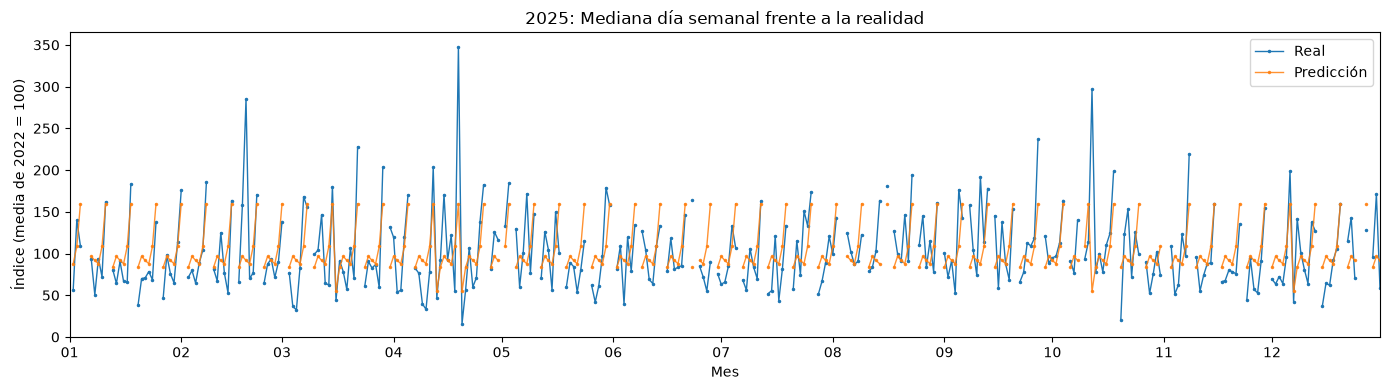

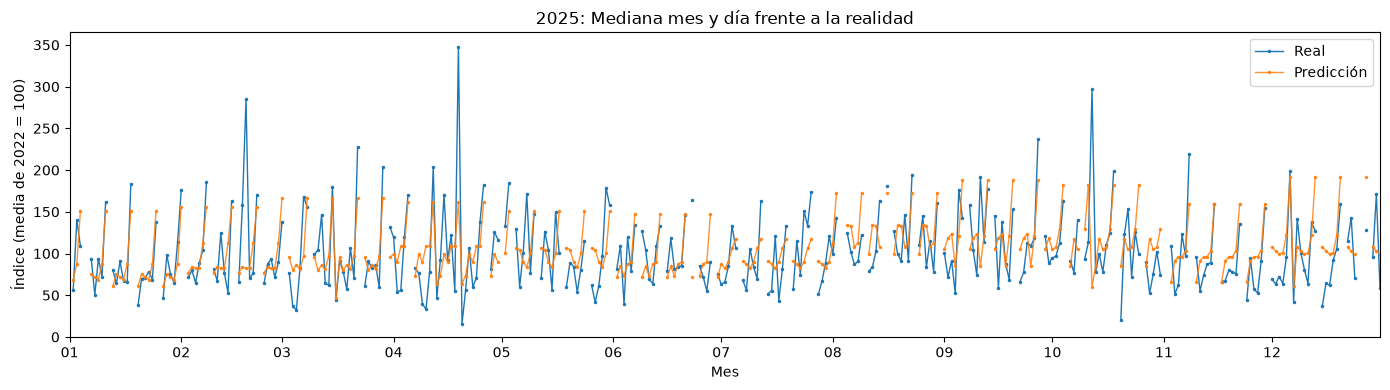

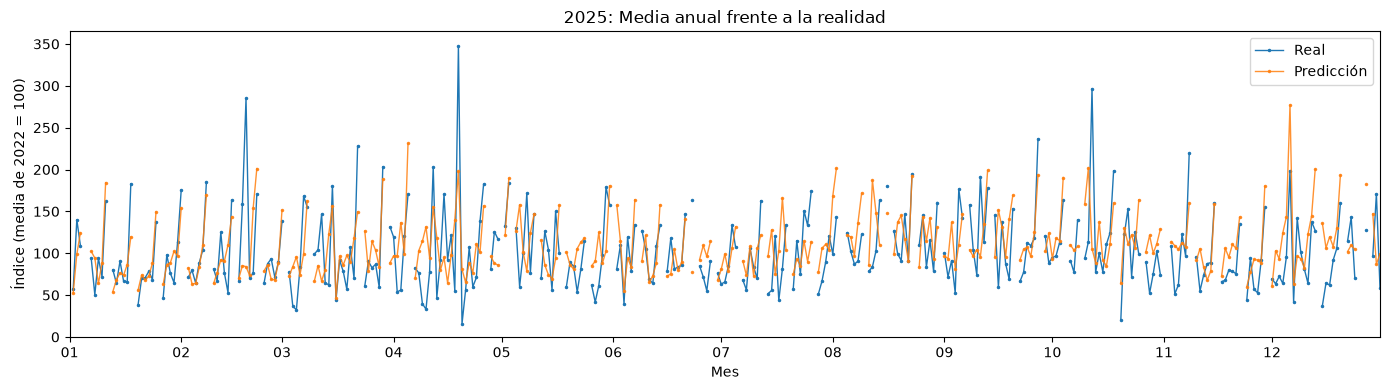

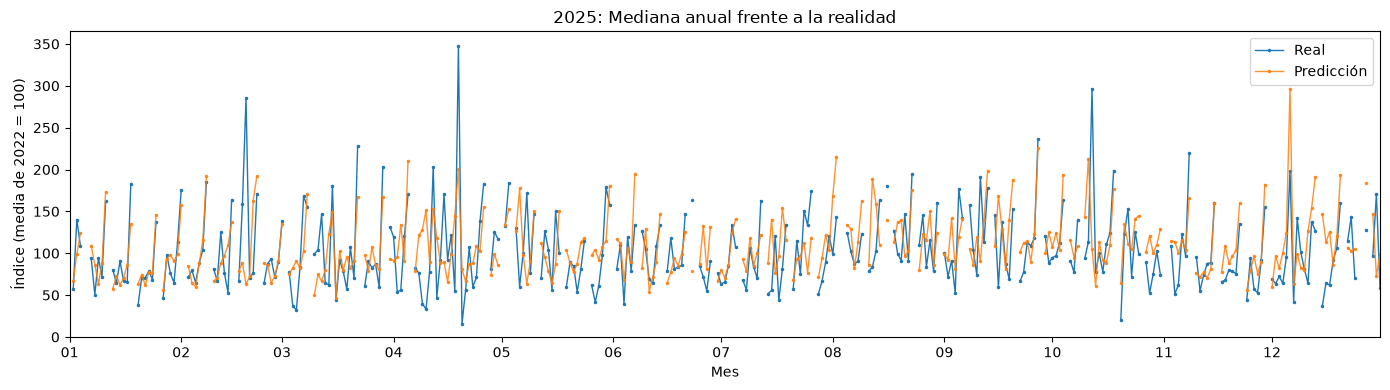

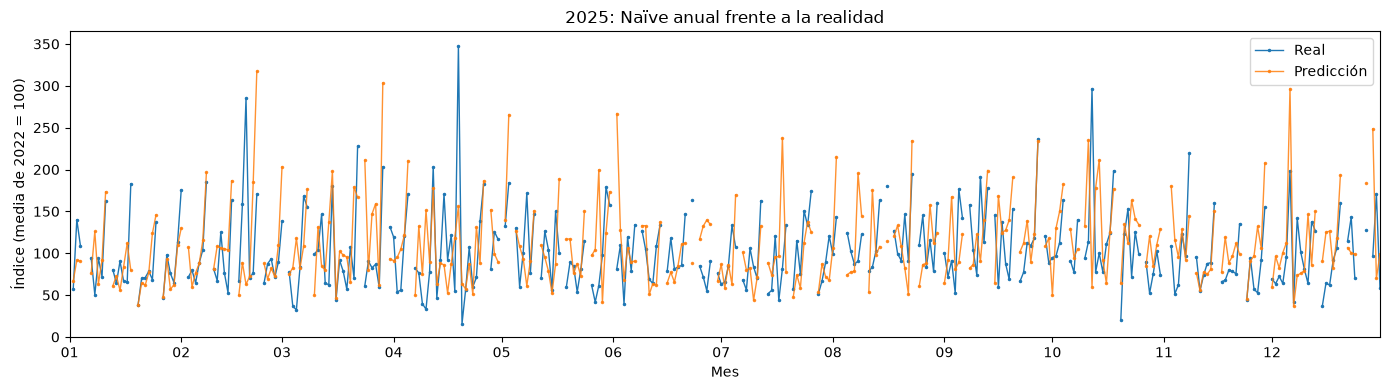

In [11]:
import matplotlib.dates as mdates

modelos = ["Mediana día semanal", "Mediana mes y día", "Media anual", "Mediana anual", "Naïve anual"]
fechas_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
limite_indice = comparacion_2025[["indice", "prediccion"]].max().max() * 1.05

for modelo in modelos:
    datos_modelo = comparacion_2025.loc[comparacion_2025["modelo"].eq(modelo)]
    if datos_modelo.empty:
        raise ValueError(f"No hay predicciones para {modelo}.")
    datos_grafica = datos_modelo.set_index("fecha").reindex(fechas_2025)
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(datos_grafica.index, datos_grafica["indice"], label="Real", color="C0",
            marker=".", markersize=3, linewidth=1)
    ax.plot(datos_grafica.index, datos_grafica["prediccion"], label="Predicción", color="C1",
            marker=".", markersize=3, linewidth=1, alpha=0.85)
    ax.set(title=f"2025: {modelo} frente a la realidad", xlabel="Mes",
           ylabel="Índice (media de 2022 = 100)", ylim=(0, limite_indice),
           xlim=(fechas_2025[0], fechas_2025[-1]))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
    ax.legend()
    fig.tight_layout()
    plt.show()

## 7. Intervalos de predicción orientativos

Una predicción puntual no indica por sí sola cuánta incertidumbre tiene. Para cada baseline construiremos un **intervalo de predicción con cobertura objetivo del 90 %**: un rango de índices en el que aspiramos a encontrar la venta real de un día abierto en aproximadamente nueve de cada diez ocasiones.

Para estimar su anchura usamos exclusivamente errores de predicciones anuales anteriores a 2025: predecimos 2023 con datos de 2022 y 2024 con datos de 2022–2023. Para cada baseline calculamos el percentil 90 de los errores absolutos diarios de esos dos años, tomando el valor observado superior si es necesario. Este margen se resta y se suma a la predicción; el límite inferior se recorta a cero porque el índice de ventas no puede ser negativo.

Los márgenes se calculan **sin las ventas de 2025**. Generamos los intervalos de todo 2025 y después los comparamos con los días que realmente abrieron. La **cobertura observada** es el porcentaje de días abiertos cuyo índice real está dentro de su intervalo; la **anchura media** se expresa en puntos de índice. También desglosamos la cobertura por día de la semana y mostramos cuántas observaciones hay en cada grupo.

**Limitaciones:** el 90 % es un objetivo, no una garantía ni una probabilidad de que una predicción puntual sea correcta. Solo hay dos cortes anuales de calibración; los errores pueden cambiar con el tiempo, el mes o el día de la semana. Usamos el mismo margen para todos los días de un baseline, por lo que la cobertura por grupo puede diferir. Los domingos tienen pocas observaciones. Además, 2025 ya se ha consultado y esta evaluación es retrospectiva, no una prueba completamente ciega.

In [12]:
NIVEL_COBERTURA = 0.90

errores_anteriores = []
for anio in [2023, 2024]:
    evaluacion = evaluar_baselines(abiertos, f"{anio}-01-01", f"{anio}-12-31")
    evaluacion["error_absoluto"] = (evaluacion["indice"] - evaluacion["prediccion"]).abs()
    errores_anteriores.append(evaluacion)
calibracion = pd.concat(errores_anteriores, ignore_index=True)

margenes = calibracion.groupby("modelo")["error_absoluto"].agg(
    dias_calibracion="size",
    margen=lambda errores: np.quantile(errores.to_numpy(), NIVEL_COBERTURA, method="higher"),
)
if set(margenes.index) != set(modelos) or not np.isfinite(margenes["margen"]).all():
    raise ValueError("Faltan errores válidos de calibración para algún baseline.")
margenes.index.name = "Baseline"
display(margenes.rename(columns={
    "dias_calibracion": "Días de calibración",
    "margen": "Margen (puntos de índice)",
}).round(2))

,Días de calibración,Margen (puntos de índice)
Baseline,,
Media anual,618,70.19
Mediana anual,618,70.19
Mediana día semanal,618,63.88
Mediana mes y día,618,61.33
Naïve anual,618,73.86


### Cobertura de los intervalos en 2025

Primero calculamos los límites para todas las fechas de 2025, como si la tienda fuera a abrir, usando solo datos y márgenes anteriores a ese año. Después comparamos los intervalos únicamente con las ventas reales de los días abiertos.

Una cobertura próxima al 90 % es deseable, pero también importa la anchura: un intervalo excesivamente ancho puede cubrir muchos días y ser poco útil. El desglose semanal ayuda a detectar diferencias, aunque los grupos pequeños, especialmente los domingos, no permiten conclusiones firmes.

In [13]:
entrenamiento_2025 = abiertos.loc[abiertos["fecha"] < pd.Timestamp("2025-01-01")]
predicciones_intervalos = predecir_estacionales(entrenamiento_2025, "2025-01-01", "2025-12-31")
intervalos = predicciones_intervalos.merge(
    margenes[["margen"]], left_on="modelo", right_index=True, validate="many_to_one"
)
intervalos["limite_inferior"] = (intervalos["prediccion"] - intervalos["margen"]).clip(lower=0)
intervalos["limite_superior"] = intervalos["prediccion"] + intervalos["margen"]

reales_2025 = abiertos.loc[abiertos["fecha"].between("2025-01-01", "2025-12-31")]
evaluacion_intervalos = intervalos.merge(reales_2025, on="fecha", how="inner", validate="many_to_one")
if len(evaluacion_intervalos) != len(modelos) * len(reales_2025) or evaluacion_intervalos.empty:
    raise ValueError("No se pudieron evaluar los intervalos sobre los mismos días abiertos.")
evaluacion_intervalos["cubierto"] = evaluacion_intervalos["indice"].between(
    evaluacion_intervalos["limite_inferior"], evaluacion_intervalos["limite_superior"]
)
evaluacion_intervalos["anchura"] = (
    evaluacion_intervalos["limite_superior"] - evaluacion_intervalos["limite_inferior"]
)

def resumen_intervalos(datos, grupos):
    resumen = datos.groupby(grupos).agg(
        dias=("cubierto", "size"),
        cobertura=("cubierto", "mean"),
        anchura=("anchura", "mean"),
    )
    resumen["cobertura"] *= 100
    return resumen.rename(columns={
        "dias": "Días abiertos",
        "cobertura": "Cobertura observada (%)",
        "anchura": "Anchura media (puntos de índice)",
    })

print("Cobertura y anchura por baseline en 2025:")
display(resumen_intervalos(evaluacion_intervalos, ["modelo"]).round(2))

evaluacion_intervalos["dia_semana"] = evaluacion_intervalos["fecha"].dt.day_of_week
por_dia_intervalos = resumen_intervalos(evaluacion_intervalos, ["modelo", "dia_semana"])
por_dia_intervalos = por_dia_intervalos.reset_index()
por_dia_intervalos["dia_semana"] = por_dia_intervalos["dia_semana"].map(dict(enumerate(DIAS)))
print("Cobertura por día de la semana:")
display(por_dia_intervalos.set_index(["modelo", "dia_semana"]).round(2))

Cobertura y anchura por baseline en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
modelo,,,
Media anual,308,90.58,139.78
Mediana anual,308,91.88,139.62
Mediana día semanal,308,95.13,127.62
Mediana mes y día,308,93.51,122.60
Naïve anual,308,87.01,144.81


Cobertura por día de la semana:


Días abiertos  Cobertura observada (%)  \
modelo              dia_semana                                           
Media anual         Lunes                  50                    94.00   
                    Martes                 51                    86.27   
                    Miércoles              52                    94.23   
                    Jueves                 49                    91.84   
                    Viernes                50                    90.00   
                    Sábado                 51                    90.20   
                    Domingo                 5                    60.00   
Mediana anual       Lunes                  50                    96.00   
                    Martes                 51                    88.24   
                    Miércoles              52                    94.23   
                    Jueves                 49                    91.84   
                    Viernes                50                    92.00   
                    Sábado                 51                    92.16   
                    Domingo                 5                    60.00   
Mediana día semanal Lunes                  50                    96.00   
                    Martes                 51                    96.08   
                    Miércoles              52                    98.08   
                    Jueves                 49                    93.88   
                    Viernes                50                    96.00   
                    Sábado                 51                    92.16   
                    Domingo                 5                    80.00   
Mediana mes y día   Lunes                  50                    94.00   
                    Martes                 51                    90.20   
                    Miércoles              52                    98.08   
                    Jueves                 49                    93.88   
                    Viernes                50                    96.00   
                    Sábado                 51                    90.20   
                    Domingo                 5                    80.00   
Naïve anual         Lunes                  50                    86.00   
                    Martes                 51                    90.20   
                    Miércoles              52                    90.38   
                    Jueves                 49                    87.76   
                    Viernes                50                    86.00   
                    Sábado                 51                    82.35   
                    Domingo                 5                    80.00   

                                Anchura media (puntos de índice)  
modelo              dia_semana                                    
Media anual         Lunes                                 138.79  
                    Martes                                140.21  
                    Miércoles                             139.64  
                    Jueves                                139.80  
                    Viernes                               140.39  
                    Sábado                                140.39  
                    Domingo                               134.29  
Mediana anual       Lunes                                 138.16  
                    Martes                                140.26  
                    Miércoles                             139.11  
                    Jueves                                139.92  
                    Viernes                               140.39  
                    Sábado                                140.39  
                    Domingo                               134.29  
Mediana día semanal Lunes                                 127.77  
                    Martes                                127.77  
                    Miércoles                             127.77  
                    

### Intervalos frente a la realidad

En cada gráfica la banda representa el intervalo orientativo del 90 %. Los puntos y las líneas muestran el índice real y la predicción en los días abiertos; los cierres aparecen como huecos. Las cinco gráficas comparten escala vertical.

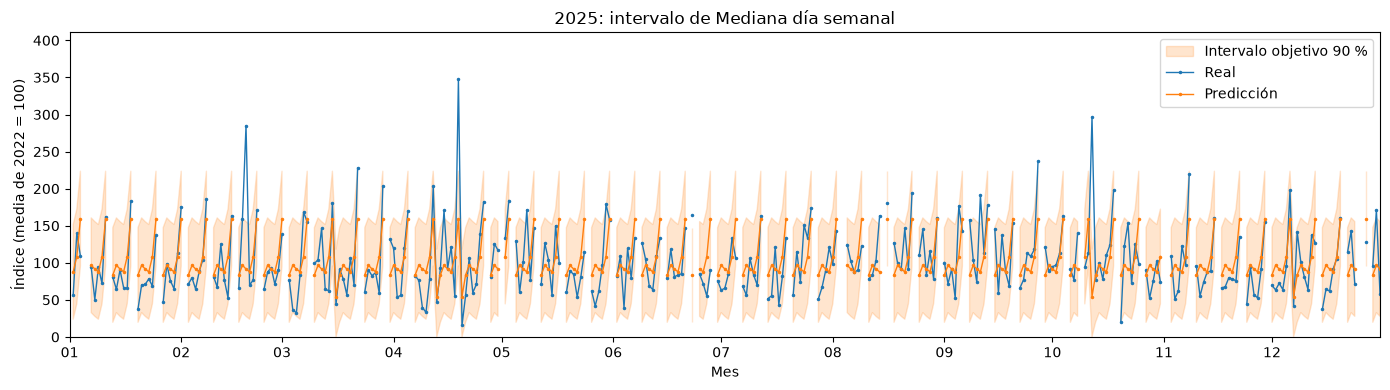

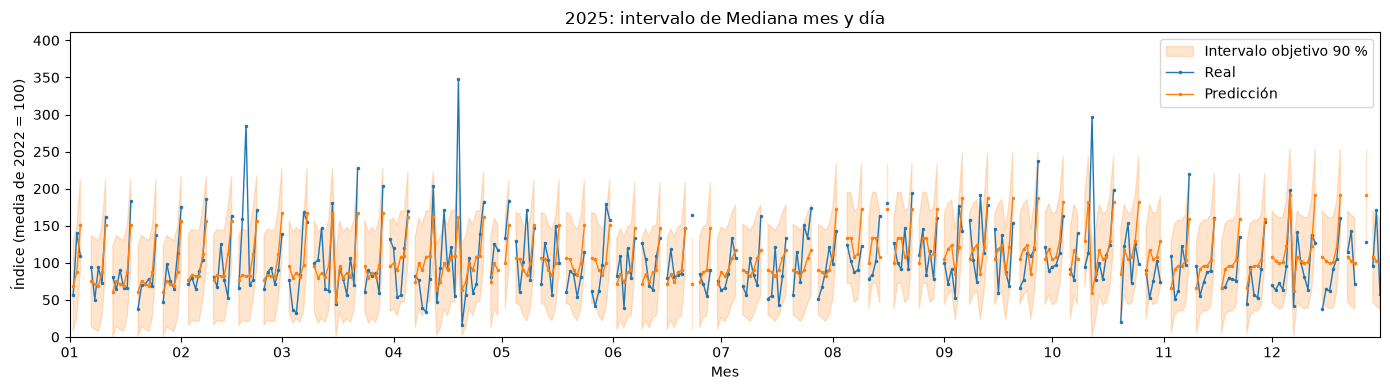

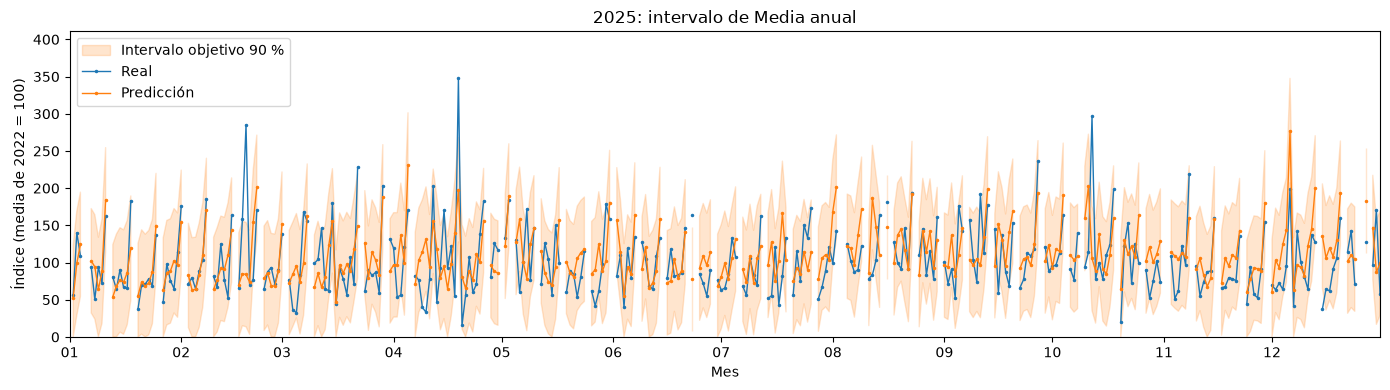

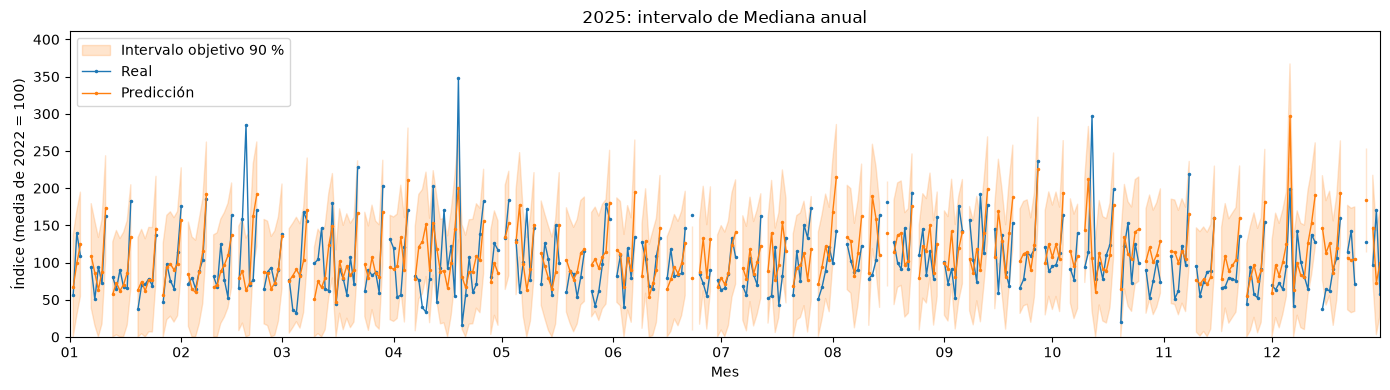

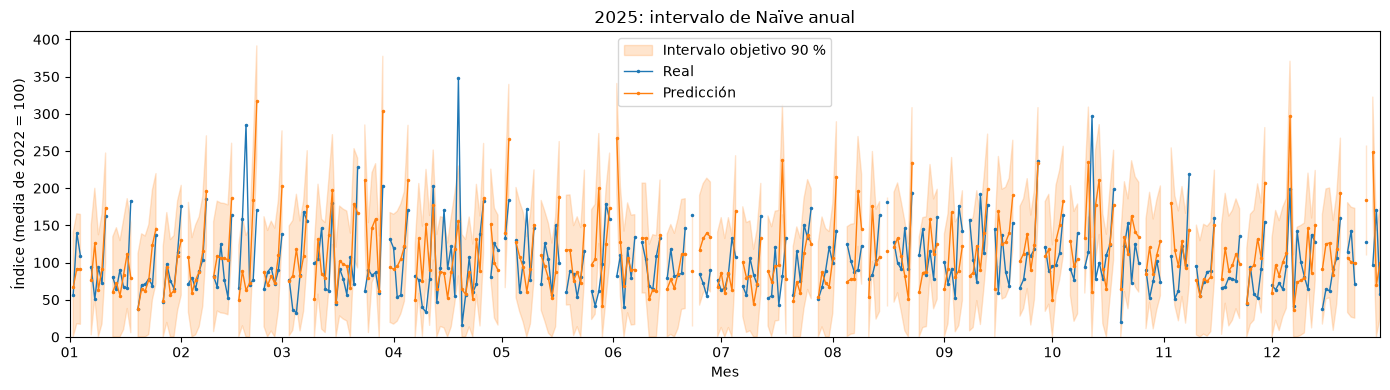

In [14]:
limite_graficas = evaluacion_intervalos[["indice", "limite_superior"]].max().max() * 1.05
for modelo in modelos:
    datos_modelo = evaluacion_intervalos.loc[evaluacion_intervalos["modelo"].eq(modelo)]
    if datos_modelo.empty:
        raise ValueError(f"No hay intervalos evaluados para {modelo}.")
    datos_grafica = datos_modelo.set_index("fecha").reindex(fechas_2025)
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.fill_between(datos_grafica.index, datos_grafica["limite_inferior"],
                    datos_grafica["limite_superior"], color="C1", alpha=0.20,
                    label="Intervalo objetivo 90 %")
    ax.plot(datos_grafica.index, datos_grafica["indice"], label="Real", color="C0",
            marker=".", markersize=3, linewidth=1)
    ax.plot(datos_grafica.index, datos_grafica["prediccion"], label="Predicción", color="C1",
            marker=".", markersize=3, linewidth=1)
    ax.set(title=f"2025: intervalo de {modelo}", xlabel="Mes",
           ylabel="Índice (media de 2022 = 100)", ylim=(0, limite_graficas),
           xlim=(fechas_2025[0], fechas_2025[-1]))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
    ax.legend()
    fig.tight_layout()
    plt.show()